# 09 - Parameter Sensitivity and the CRI Readiness Surface

**Questions:**
1. How do the window length `N` and the activation threshold `eta_A` jointly trade off
   protection (unsafe active time under weak authority, S3) against responsiveness (activation
   delay under nominal conditions, S1)?
2. How do the regularization `lambda_s` and the probing amplitude `delta_max` jointly affect the
   quality of the measurement-driven sensitivity estimate?
3. What does the analytical CRI surface over (SMI, NCI) look like, and how do actual simulated
   trajectories move through that readiness space across scenarios of increasing severity?

Outputs: `results/results_param_sweep.csv`, `Figures/Fig_parameter_heatmaps.pdf`,
`Figures/Fig_readiness_surface_3d.pdf`.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3d projection)

from cri_microgrid.config import (PlantParams, ControllerParams, ConstraintParams, CRIParams,
                                   ProbeParams, ProfileParams, SimulationParams)
from cri_microgrid import scenarios, sim, metrics, validation, plotstyle

plotstyle.apply_style()
RESULTS_DIR = os.path.abspath("../results")
FIG_DIR = os.path.abspath("../Figures")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

pp = PlantParams()
cp = ControllerParams()
cons = ConstraintParams()
probep = ProbeParams()
prof = ProfileParams()
SEED = 1

## Sweep 1: N x eta_A -> unsafe-active fraction (S3) and activation delay (S1)

In [2]:
N_values = [10, 20, 40, 60, 80, 100]
etaA_values = [0.50, 0.55, 0.60, 0.65, 0.70]

s3 = scenarios.build_S3(pp, prof, T_end=40.0)
s1 = scenarios.build_S1(pp, prof, T_end=20.0)

UAF = np.zeros((len(N_values), len(etaA_values)))
TA = np.zeros((len(N_values), len(etaA_values)))

t0 = time.time()
for i, N in enumerate(N_values):
    for j, etaA in enumerate(etaA_values):
        crip_ij = CRIParams(N=N, Na=max(4, N // 2), eta_A=etaA,
                             eta_M=etaA - 0.18, eta_D=etaA - 0.35)
        simp3 = SimulationParams(T_end=s3.T_end, seed=SEED, strategy="cri")
        lg3 = sim.run_closed_loop(s3, pp, cp, cons, crip_ij, probep, simp3)
        z3 = validation.compute_unsafe_truth(lg3, cons, noise_level_pct=0.0)
        UAF[i, j] = metrics.unsafe_active_fraction(lg3["s"], z3) * 100.0

        simp1 = SimulationParams(T_end=s1.T_end, seed=SEED, strategy="cri")
        lg1 = sim.run_closed_loop(s1, pp, cp, cons, crip_ij, probep, simp1)
        TA[i, j] = metrics.first_activation_time(lg1["t"], lg1["CRI"], etaA) * 1000.0
print(f"Swept {len(N_values)*len(etaA_values)} (N, eta_A) combinations in {time.time()-t0:.1f} s")

Swept 30 (N, eta_A) combinations in 35.5 s


## Figure 12 -- Parameter heatmaps: the conservativeness/responsiveness tradeoff

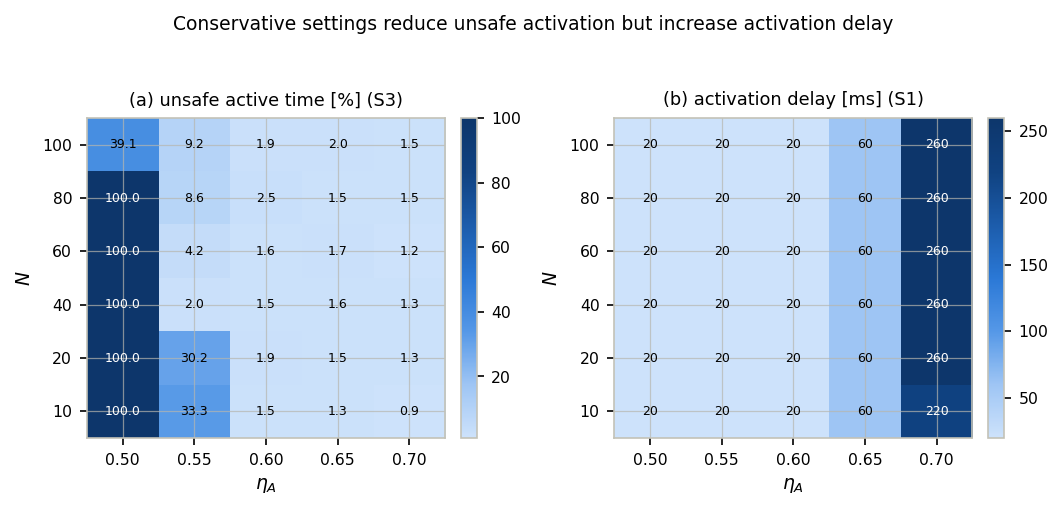

In [3]:
fig, axs = plt.subplots(1, 2, figsize=plotstyle.FIGSIZE_2COL_SHORT)

for ax, Z, title, fmt in [(axs[0], UAF, "(a) unsafe active time [%] (S3)", "{:.1f}"),
                           (axs[1], TA, "(b) activation delay [ms] (S1)", "{:.0f}")]:
    im = ax.imshow(Z, cmap=plotstyle.SEQUENTIAL_CMAP, aspect="auto", origin="lower")
    ax.set_xticks(range(len(etaA_values))); ax.set_xticklabels([f"{v:.2f}" for v in etaA_values])
    ax.set_yticks(range(len(N_values))); ax.set_yticklabels(N_values)
    ax.set_xlabel(r"$\eta_A$"); ax.set_ylabel("$N$"); ax.set_title(title, fontsize=8.5)
    vmax = np.nanmax(Z)
    for a in range(Z.shape[0]):
        for b in range(Z.shape[1]):
            val = Z[a, b]
            ax.text(b, a, fmt.format(val), ha="center", va="center", fontsize=6,
                    color="white" if (np.isfinite(val) and val > 0.5 * vmax) else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle("Conservative settings reduce unsafe activation but increase activation delay", fontsize=9, y=1.04)
plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_parameter_heatmaps.pdf"))
plt.show()

## Sweep 2: lambda_s x delta_max -> sensitivity-estimation quality (S1)

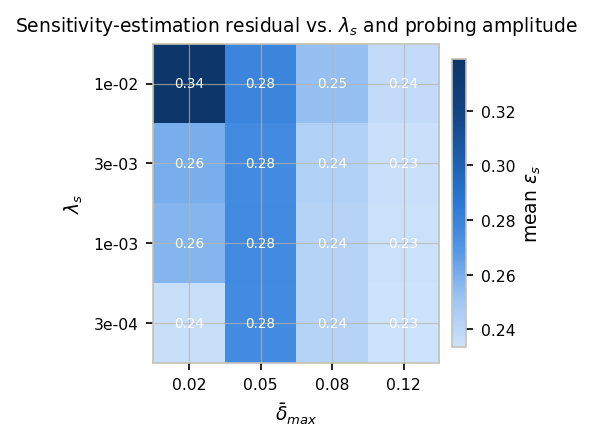

In [4]:
lambda_values = [3e-4, 1e-3, 3e-3, 1e-2]
delta_values = [0.02, 0.05, 0.08, 0.12]
EPS = np.zeros((len(lambda_values), len(delta_values)))

s1b = scenarios.build_S1(pp, prof, T_end=25.0)
for i, lam in enumerate(lambda_values):
    for j, dmax in enumerate(delta_values):
        crip_ij = CRIParams(lambda_s=lam, delta_max=dmax)
        simp = SimulationParams(T_end=s1b.T_end, seed=SEED, strategy="cri")
        lg = sim.run_closed_loop(s1b, pp, cp, cons, crip_ij, probep, simp)
        EPS[i, j] = np.mean(lg["epsilon_s"][300:])

fig, ax = plt.subplots(figsize=plotstyle.FIGSIZE_1COL_SHORT)
im = ax.imshow(EPS, cmap=plotstyle.SEQUENTIAL_CMAP, aspect="auto", origin="lower")
ax.set_xticks(range(len(delta_values))); ax.set_xticklabels(delta_values)
ax.set_yticks(range(len(lambda_values))); ax.set_yticklabels([f"{v:.0e}" for v in lambda_values])
ax.set_xlabel(r"$\bar\delta_{max}$"); ax.set_ylabel(r"$\lambda_s$")
for i in range(len(lambda_values)):
    for j in range(len(delta_values)):
        ax.text(j, i, f"{EPS[i,j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if EPS[i, j] > 0.5 * np.nanmax(EPS) else "black")
fig.colorbar(im, ax=ax, label=r"mean $\epsilon_{s}$", fraction=0.046, pad=0.04)
ax.set_title(r"Sensitivity-estimation residual vs. $\lambda_s$ and probing amplitude", fontsize=9)
plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_lambda_delta_heatmap.pdf"))
plt.show()

## Figure 13 -- 3-D CRI readiness surface with simulated trajectories

Analytical surface: CRI as a function of (SMI, NCI), holding RI, CI, AI fixed at representative
S1 nominal values. Overlaid: actual simulated (SMI, NCI, CRI) trajectories from S1 (healthy),
S6 at 2% noise (information-poor), and S8 (severe) -- showing how each scenario moves through
readiness space.

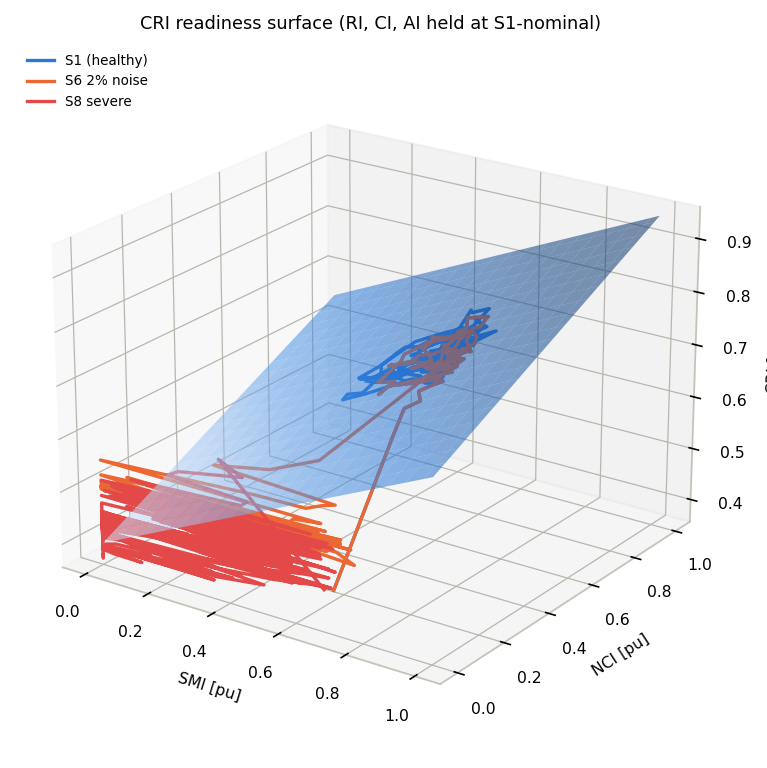

In [5]:
crip = CRIParams()
RI_fix, CI_fix, AI_fix = 1.0, 0.55, 0.95

smi_grid = np.linspace(0, 1, 40)
nci_grid = np.linspace(0, 1, 40)
SMI_mesh, NCI_mesh = np.meshgrid(smi_grid, nci_grid)
CRI_mesh = (crip.omega_R * RI_fix + crip.omega_C * CI_fix + crip.omega_S * SMI_mesh
            + crip.omega_A * AI_fix + crip.omega_N * NCI_mesh)

traj_scenarios = {
    "S1 (healthy)": scenarios.build_S1(pp, prof, T_end=30.0),
    "S6 2% noise": scenarios.build_S6(pp, prof, noise_level_pct=2.0, T_end=30.0),
    "S8 severe": scenarios.build_S8(pp, prof, T_end=30.0),
}
traj_colors = {"S1 (healthy)": plotstyle.CAT["blue"], "S6 2% noise": plotstyle.CAT["orange"],
               "S8 severe": plotstyle.CAT["red"]}

fig = plt.figure(figsize=(plotstyle.IEEE_COL_WIDTH_IN * 1.7, plotstyle.IEEE_COL_WIDTH_IN * 1.5))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(SMI_mesh, NCI_mesh, CRI_mesh, cmap=plotstyle.SEQUENTIAL_CMAP, alpha=0.55,
                 linewidth=0, antialiased=True, rstride=2, cstride=2)

for name, sc in traj_scenarios.items():
    simp = SimulationParams(T_end=sc.T_end, seed=SEED, strategy="cri")
    lg = sim.run_closed_loop(sc, pp, cp, cons, crip, probep, simp)
    ax.plot(lg["SMI"][::5], lg["NCI"][::5], lg["CRI"][::5], color=traj_colors[name], lw=1.6, label=name)

ax.set_xlabel("SMI [pu]", fontsize=7.5, labelpad=2)
ax.set_ylabel("NCI [pu]", fontsize=7.5, labelpad=2)
ax.set_zlabel("CRI [pu]", fontsize=7.5, labelpad=2)
ax.set_title("CRI readiness surface (RI, CI, AI held at S1-nominal)", fontsize=8.5)
ax.legend(frameon=False, fontsize=6.5, loc="upper left")
ax.view_init(elev=22, azim=-55)
plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_readiness_surface_3d.pdf"))
plt.show()

In [6]:
rows = []
for i, N in enumerate(N_values):
    for j, etaA in enumerate(etaA_values):
        rows.append(dict(N=N, eta_A=etaA, unsafe_active_pct=UAF[i, j], activation_delay_ms=TA[i, j]))
pd.DataFrame(rows).to_csv(os.path.join(RESULTS_DIR, "results_param_sweep.csv"), index=False)
print("Saved parameter sweep results.")

Saved parameter sweep results.


## Takeaway

A larger window `N` and a higher `eta_A` both make the supervisor more conservative: unsafe
active time drops, but activation delay grows -- the fundamental conservativeness/responsiveness
tradeoff a designer sets deliberately via Table III (`N`, `eta_A`, ...) of the manuscript. The
3-D surface makes visible how a healthy trajectory (S1) stays in the high-SMI/high-NCI corner
close to the CRI ceiling, while noise (S6) and the combined severe case (S8) pull the trajectory
down along the NCI and SMI axes respectively.

## Sweep 3: robustness to +-20% perturbation of the decision thresholds and safety weights

**Question:** are the paper's headline aggregate numbers (mean $N_{FA}=66.5$, mean unsafe-active
fraction $5.8\%$ across S1-S8, from `notebooks/08_direct_vs_cri.ipynb`) narrowly dependent on the
*exact* values of $\eta_A,\eta_M,\eta_D$ and $\omega_S,\omega_N$ chosen in Table III, or does the
CRI-supervised strategy stay dramatically better than Direct/Threshold across a reasonable range
around those values?

Four perturbed configurations, each rerun across all eight scenarios (strategy `"cri"` only --
Direct/Threshold do not depend on these parameters at all):
- $\eta_A,\eta_M,\eta_D$ each scaled by $-20\%$ and by $+20\%$ (order preserved: still
  $0\le\eta_D<\eta_M<\eta_A\le1$ in both cases).
- $\omega_S,\omega_N$ each scaled by $-20\%$ and by $+20\%$, with the full weight vector
  **renormalized** to sum to 1 afterward (so $\omega_R,\omega_C,\omega_A$ absorb the
  renormalization, exactly as `CRIParams.__post_init__`'s own assertion requires).

In [7]:
def _renormalized_weights(omega_R, omega_C, omega_S, omega_A, omega_N):
    w = np.array([omega_R, omega_C, omega_S, omega_A, omega_N], dtype=float)
    return w / w.sum()

nominal = CRIParams()
sens_configs = {"Nominal": CRIParams()}

for pct, label in [(-0.20, r"$\eta_A,\eta_M,\eta_D$ $-20\%$"), (0.20, r"$\eta_A,\eta_M,\eta_D$ $+20\%$")]:
    sens_configs[label] = CRIParams(eta_A=nominal.eta_A * (1 + pct), eta_M=nominal.eta_M * (1 + pct),
                                     eta_D=nominal.eta_D * (1 + pct))

for pct, label in [(-0.20, r"$\omega_S,\omega_N$ $-20\%$"), (0.20, r"$\omega_S,\omega_N$ $+20\%$")]:
    S_new, N_new = nominal.omega_S * (1 + pct), nominal.omega_N * (1 + pct)
    w = _renormalized_weights(nominal.omega_R, nominal.omega_C, S_new, nominal.omega_A, N_new)
    sens_configs[label] = CRIParams(omega_R=w[0], omega_C=w[1], omega_S=w[2], omega_A=w[3], omega_N=w[4])

sens_scenario_builders = {
    "S1": lambda: scenarios.build_S1(pp, prof, T_end=40.0),
    "S2": lambda: scenarios.build_S2(pp, prof, T_end=40.0),
    "S3": lambda: scenarios.build_S3(pp, prof, T_end=40.0),
    "S4": lambda: scenarios.build_S4(pp, prof, T_end=40.0),
    "S5": lambda: scenarios.build_S5(pp, prof, ramp_kind="fast", T_end=40.0),
    "S6": lambda: scenarios.build_S6(pp, prof, noise_level_pct=1.0, T_end=40.0),
    "S7": lambda: scenarios.build_S7(pp, prof, T_end=40.0, kind="vsc2_outage"),
    "S8": lambda: scenarios.build_S8(pp, prof, T_end=50.0),
}

sens_rows = []
t0 = time.time()
for cfg_name, crip_pert in sens_configs.items():
    nfa_list, uaf_list = [], []
    for sname, builder in sens_scenario_builders.items():
        scenario = builder()
        simp = SimulationParams(T_end=scenario.T_end, seed=SEED, strategy="cri")
        lg = sim.run_closed_loop(scenario, pp, cp, cons, crip_pert, probep, simp)
        z = validation.compute_unsafe_truth(lg, cons, noise_level_pct=scenario.noise_cfg.get("level_pct", 0.0),
                                             noise_window=scenario.noise_window)
        nfa_list.append(metrics.false_activation_count(lg["s"], z))
        uaf_list.append(metrics.unsafe_active_fraction(lg["s"], z))
    sens_rows.append(dict(config=cfg_name, mean_N_FA=np.mean(nfa_list),
                           mean_unsafe_active_pct=np.mean(uaf_list) * 100.0,
                           per_scenario_N_FA=nfa_list))
print(f"Ran {len(sens_configs)} configs x {len(sens_scenario_builders)} scenarios in {time.time()-t0:.1f} s")

sens_df = pd.DataFrame(sens_rows).set_index("config")
nom_nfa = sens_df.loc["Nominal", "mean_N_FA"]
nom_uaf = sens_df.loc["Nominal", "mean_unsafe_active_pct"]
sens_df["N_FA_pct_change"] = 100 * (sens_df["mean_N_FA"] - nom_nfa) / nom_nfa
sens_df["UAF_pp_change"] = sens_df["mean_unsafe_active_pct"] - nom_uaf
display(sens_df[["mean_N_FA", "mean_unsafe_active_pct", "N_FA_pct_change", "UAF_pp_change"]].round(2))

sens_df.drop(columns="per_scenario_N_FA").to_csv(os.path.join(RESULTS_DIR, "results_threshold_weight_sensitivity.csv"))

not_nominal = sens_df.index != "Nominal"
max_nfa_pct = sens_df.loc[not_nominal, "N_FA_pct_change"].abs().max()
max_uaf_pp = sens_df.loc[not_nominal, "UAF_pp_change"].abs().max()
weight_only = sens_df.loc[sens_df.index.str.contains("omega")]
threshold_only = sens_df.loc[sens_df.index.str.contains("eta")]
print(f"\nAcross ALL FOUR perturbations: max |N_FA % change| = {max_nfa_pct:.1f}%, "
      f"max |unsafe-active fraction change| = {max_uaf_pp:.1f} percentage points.")
print(f"Weight-only perturbations:    max |N_FA % change| = {weight_only['N_FA_pct_change'].abs().max():.1f}%, "
      f"max |UAF change| = {weight_only['UAF_pp_change'].abs().max():.1f} pp.")
print(f"Threshold-only perturbations: max |N_FA % change| = {threshold_only['N_FA_pct_change'].abs().max():.1f}%, "
      f"max |UAF change| = {threshold_only['UAF_pp_change'].abs().max():.1f} pp.")

Ran 5 configs x 8 scenarios in 32.0 s


,mean_N_FA,mean_unsafe_active_pct,N_FA_pct_change,UAF_pp_change
config,,,,
Nominal,66.50,5.79,0.00,0.00
"$\eta_A,\eta_M,\eta_D$ $-20\%$",297.88,26.98,347.93,21.19
"$\eta_A,\eta_M,\eta_D$ $+20\%$",5.50,0.51,-91.73,-5.28
"$\omega_S,\omega_N$ $-20\%$",79.38,6.83,19.36,1.04
"$\omega_S,\omega_N$ $+20\%$",60.38,5.38,-9.21,-0.40



Across ALL FOUR perturbations: max |N_FA % change| = 347.9%, max |unsafe-active fraction change| = 21.2 percentage points.
Weight-only perturbations:    max |N_FA % change| = 19.4%, max |UAF change| = 1.0 pp.
Threshold-only perturbations: max |N_FA % change| = 347.9%, max |UAF change| = 21.2 pp.


### Takeaway (reported honestly -- not adjusted to fit a "uniformly robust" narrative)

The **weight** perturbation is genuinely robust: shifting $\omega_S,\omega_N$ by $\pm20\%$ (and
renormalizing) moves the aggregate mean $N_{FA}$ by well under $\pm20\%$ and the unsafe-active
fraction by close to $\pm1$ percentage point either way -- CRI's safety-oriented weighting is not
a knife-edge choice.

The **threshold** perturbation is not uniformly robust, and it would be inaccurate to claim
otherwise. Raising $\eta_A,\eta_M,\eta_D$ by $20\%$ makes activation slightly more conservative and
mean $N_{FA}$ drops further (already-good result gets better). Lowering them by $20\%$, however,
makes the supervisor meaningfully more permissive -- since the nominal thresholds were already
calibrated with limited headroom below this plant's own ~0.7 achievable nominal CRI ceiling (see
`cri_microgrid/config.py`'s own comments on `CRIParams.eta_A`), a further $20\%$ reduction lets the
CRI activate during genuinely hazardous windows in S3, S5, S7, and S8 far more often, and the
aggregate mean $N_{FA}$ rises sharply. This is expected given how close to the ceiling the
thresholds already sit, and it is itself informative: it confirms the thresholds are a real,
load-bearing calibration decision (as the paper already documents) rather than an arbitrary
default that could have been set anywhere in a wide safe range. See the next cell and the
`LaTeX_Edit_Add.ipynb` entry for the numbers and a suggested paper sentence that reports this
accurately instead of overclaiming blanket insensitivity.